# 答案配平、数值回归头、去词汇化:balnum_v1 与 delex_v1

**目的**:模型不看图也远高于随机(留出集随机 29.9,全零场景约 44)。这份报告检查三项改动能否把模型从"靠先验答题"推向"靠场景答题"。

| 实验 | 改动 | 对照 |
|---|---|---|
| balnum_v1 | slots_v2 + 按答案频率倒数加权 + 数值回归头 | slots_v2 |
| delex_v1 | balnum_v1 + 一半训练题去词汇化(物体名换成 object A / B / ...) | balnum_v1 |

三个模型的训练数据、步数(6870 步,3 张卡)、初始权重相同。评测:留出集 6,786 题;VSI-Bench test 选择题 1,845 题、数值题 1,684 题(都是带位姿的 ScanNet / ScanNet++ 部分)。

**对照输入**:real 真场景;shuffled 换成同批另一题的场景;zero 场景 token 全零;slots_swapped 物体槽换成另一题的;slots_none 去掉物体 token。

## 总结

- **VSI-Bench test(带位姿的 3,529 题)**:8 个任务平均 balnum_v1 35.0、delex_v1 37.0;选择题 4 任务平均 hardneg_v1 34.1、slots_v2 32.9、balnum_v1 29.0、delex_v1 35.5。选择题分数换场景后不降。
- **MMSI-Bench(VGGT 位姿)**:25.1 / 29.4 / 27.0 / 23.4,随机 25;与场景和位姿都无关。
- **配平去掉了一部分答案先验,但模型没有改用场景来补**:全零场景 44.4 → 38.0,真场景同步 48.1 → 42.9;真场景减换场景的差从 3.6 缩到 1.9。
- **数值头只在房间面积上用到了场景**:MRA 53.1,换场景 27.5,总答中位数 29.1。计数 42.5 低于中位数基线 59.6;物体尺寸 35.0 与换场景相同;绝对距离没有信号。
- **去掉名字后模型回到随机水平**:delex_v1 在去词汇化的留出集上 30.7(随机 29.9),真场景、换场景、换槽相同。带名字时的约 42 分基本来自名字和答案先验。
- **一半一半训练没有让物体 token 承担"指明是哪个物体"**:没见过代号的 balnum_v1 在去词汇化评测上 29.1,delex_v1 30.7,差 1.6 个点。
- **一半一半没有伤害带名字的评测**:留出集长答案 42.1 对 42.9,短答案 39.3 对 33.6。
- **VSI-Bench 选择题的升降不是空间能力的变化**:33.6 / 29.0 / 35.7,但三个模型的真场景和换场景分数都相同;方向中等题 35.0 / 14.0 / 44.0 这样的波动来自选项偏向。
- 每个 VSI-Bench 题型只有 90–620 题,3 个点以内的差别不算数。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
load = lambda path: json.load(open(path))
RUNS = {"slots_v2": load("../../slots_v2/results/eval_final.json"),
        "balnum_v1": load("../results/eval_final.json"),
        "delex_v1": load("../../delex_v1/results/eval_final.json")}
DELEX = {"balnum_v1": load("../results/eval_final_delex.json"),
         "delex_v1": load("../../delex_v1/results/eval_final_delex.json")}
MODES = ["real", "shuffled", "zero", "slots_swapped", "slots_none"]
W = load("../data/answer_weights.json")

def score(v):
    if v is None: return None
    if isinstance(v, dict): return 100 * v.get("acc", v.get("mra"))
    return 100 * v

def by_mode(runs, ds, key):
    return pd.DataFrame({name: {m: score(r[m].get(ds, {}).get(key)) for m in MODES} for name, r in runs.items()}).T.astype(float).round(1)

def by_type(runs, ds, keep=lambda k: True):
    first = next(iter(runs.values()))
    rows = {}
    for k, v in first["real"][ds].items():
        if not keep(k): continue
        row = {"题数": v.get("rows") if isinstance(v, dict) else None,
               "随机": 100 * v["chance"] if isinstance(v, dict) and "chance" in v else None}
        for name, r in runs.items():
            real, shuf = score(r["real"][ds].get(k)), score(r["shuffled"][ds].get(k))
            row[f"{name} real"], row[f"{name} real-shuffled"] = real, None if real is None else real - shuf
        rows[k.replace("type/", "")] = row
    return pd.DataFrame(rows).T.dropna(axis=1, how="all").astype(float).round(1)

## 0 基准评测:VSI-Bench 与 MMSI-Bench

对外可比的是这两个评测集;后面各节的留出集只用作对照。

### 0.1 VSI-Bench(官方 8 个任务的排法)

选择题是准确率,数值题是 MRA;相对方向取 easy / medium / hard 三档平均。hardneg_v1 和 slots_v2 没有数值头,答不了数值题。

**覆盖范围**:模型需要相机位姿,只评了 ScanNet 和 ScanNet++ 的题(test 3,529 道)。VSI-Bench 全集 5,130 道,ARKitScenes 的 1,601 道服务器上没有位姿,没有评。这些数字不能直接和论文里的全集分数比。

In [2]:
H = load("../../hardneg_v1/results/eval_final.json")
ALL = {"hardneg_v1": H, **RUNS}
MC = {"相对距离": ["object_rel_distance"], "相对方向": ["object_rel_direction_easy", "object_rel_direction_medium", "object_rel_direction_hard"],
      "路线规划": ["route_planning"], "出现顺序": ["obj_appearance_order"]}
NUM = {"计数": "object_counting", "绝对距离": "object_abs_distance", "物体尺寸": "object_size_estimation", "房间面积": "room_size_estimation"}

def vsibench(split, mode):
    table = {}
    for name, r in ALL.items():
        mc = r[mode][f"vsibench_{split}_posed_f8"]
        col = {task: sum(100 * mc["type/" + k] for k in keys) / len(keys) for task, keys in MC.items()}
        col["选择题 4 任务平均"] = sum(col.values()) / 4
        numeric = r[mode].get(f"vsibench_{split}_numeric_posed_f8")
        if numeric:
            col.update({task: 100 * numeric["type/" + k]["mra"] for task, k in NUM.items()})
            col["8 任务平均"] = (4 * col["选择题 4 任务平均"] + sum(col[t] for t in NUM)) / 8
        table[name] = col
    return pd.DataFrame(table).round(1)

for split in ("test", "debiased"):
    for mode, label in (("real", "真场景"), ("shuffled", "换成另一题的场景")):
        print(f"VSI-Bench {split},{label}"); display(vsibench(split, mode))

VSI-Bench test,真场景


,hardneg_v1,slots_v2,balnum_v1,delex_v1
相对距离,26.2,32.8,25.0,28.5
相对方向,35.9,34.6,27.7,39.8
路线规划,33.3,26.7,24.4,33.3
出现顺序,40.9,37.5,39.0,40.5
选择题 4 任务平均,34.1,32.9,29.0,35.5
计数,NaN,NaN,42.5,36.3
绝对距离,NaN,NaN,33.1,33.6
物体尺寸,NaN,NaN,35.0,35.6
房间面积,NaN,NaN,53.1,48.0
8 任务平均,NaN,NaN,35.0,37.0


VSI-Bench test,换成另一题的场景


,hardneg_v1,slots_v2,balnum_v1,delex_v1
相对距离,24.9,34.6,25.0,27.8
相对方向,36.6,35.0,27.5,40.4
路线规划,31.1,27.8,32.2,38.9
出现顺序,40.1,37.2,38.3,39.8
选择题 4 任务平均,33.2,33.7,30.8,36.7
计数,NaN,NaN,37.6,32.8
绝对距离,NaN,NaN,31.5,31.5
物体尺寸,NaN,NaN,35.2,34.4
房间面积,NaN,NaN,27.5,26.7
8 任务平均,NaN,NaN,31.9,34.0


VSI-Bench debiased,真场景


,hardneg_v1,slots_v2,balnum_v1,delex_v1
相对距离,25.8,29.2,28.7,33.5
相对方向,40.4,37.6,44.6,40.3
路线规划,34.9,28.6,27.0,39.7
出现顺序,36.2,32.1,33.6,33.6
选择题 4 任务平均,34.3,31.9,33.5,36.8
计数,NaN,NaN,44.9,43.2
绝对距离,NaN,NaN,23.1,25.0
物体尺寸,NaN,NaN,31.0,28.5
房间面积,NaN,NaN,53.6,47.1
8 任务平均,NaN,NaN,35.8,36.4


VSI-Bench debiased,换成另一题的场景


,hardneg_v1,slots_v2,balnum_v1,delex_v1
相对距离,26.3,34.9,29.7,39.2
相对方向,37.7,36.8,43.5,34.1
路线规划,28.6,31.7,33.3,42.9
出现顺序,36.8,32.7,31.1,32.1
选择题 4 任务平均,32.3,34.1,34.4,37.1
计数,NaN,NaN,36.2,38.5
绝对距离,NaN,NaN,20.8,21.5
物体尺寸,NaN,NaN,30.7,27.9
房间面积,NaN,NaN,20.7,20.8
8 任务平均,NaN,NaN,30.8,32.1


- **delex_v1 在 VSI-Bench 上最高**:test 8 个任务平均 37.0,选择题平均 35.5(hardneg_v1 34.1,slots_v2 32.9,balnum_v1 29.0)。
- **选择题分数与场景无关**:四个模型换场景后选择题平均都不降(delex_v1 36.7)。所以选择题上的差别不是空间能力的差别。
- **8 个任务平均里来自场景的部分是数值题**:balnum_v1 35.0 对换场景 31.9,delex_v1 37.0 对 34.0,几乎全部来自房间面积。

### 0.2 MMSI-Bench

1,000 道四选一(随机 25),每题 2–10 张无位姿的图,来自多个数据集。模型需要位姿,所以用 VGGT 估计(只用于这个评测集;结果存在 `vjepa201/source_data/mmsibench_vggt/poses.jsonl`,原数据集不动;每题最多取前 8 张图)。"占位相机"是每个视角填同一个相机的下限参照。作业 `jepa3d/trainbatch/mmsibench_eval.sbatch`,结果在 `experiments/mmsibench_eval/results`。

In [3]:
MM = {c: {r: load(f"../../mmsibench_eval/results/{c}/{r}.json") for r in ALL} for c in ("vggt", "placeholder")}
pick = lambda d, m: next(v for k, v in d[m].items() if k.startswith("mmsibench"))
rows = {}
for c, label in (("vggt", "VGGT 位姿"), ("placeholder", "占位相机")):
    for r, d in MM[c].items():
        rows[f"{r},{label}"] = {m: 100 * pick(d, m)["all"] for m in MODES if m in d}
print("MMSI-Bench 总分(随机 25)"); display(pd.DataFrame(rows).T.round(1))
print("各题型,VGGT 位姿,真场景")
pd.DataFrame({r: {k.replace("type/", ""): 100 * v for k, v in pick(d, "real").items()} for r, d in MM["vggt"].items()}).round(1)

MMSI-Bench 总分(随机 25)


,real,shuffled,zero,slots_swapped,slots_none
"hardneg_v1,VGGT 位姿",25.1,23.8,21.8,NaN,NaN
"slots_v2,VGGT 位姿",29.4,30.7,30.1,28.9,27.8
"balnum_v1,VGGT 位姿",27.0,26.1,26.8,26.6,24.6
"delex_v1,VGGT 位姿",23.4,23.5,23.6,24.7,23.4
"hardneg_v1,占位相机",24.8,23.6,21.8,NaN,NaN
"slots_v2,占位相机",29.3,28.6,30.3,28.4,27.1
"balnum_v1,占位相机",25.8,25.5,27.0,26.9,24.9
"delex_v1,占位相机",23.1,23.3,23.5,25.1,25.7


各题型,VGGT 位姿,真场景


,hardneg_v1,slots_v2,balnum_v1,delex_v1
all,25.1,29.4,27.0,23.4
Attribute (Appr.),16.7,25.8,21.2,24.2
Attribute (Meas.),28.1,23.4,17.2,15.6
MSR,24.7,27.3,29.8,25.3
Motion (Cam.),24.3,37.8,31.1,18.9
Motion (Obj.),26.3,27.6,35.5,27.6
Positional Relationship (Cam.–Cam.),25.8,30.1,31.2,20.4
Positional Relationship (Cam.–Obj.),34.9,25.6,29.1,26.7
Positional Relationship (Cam.–Reg.),24.1,32.5,18.1,20.5
Positional Relationship (Obj.–Obj.),22.3,37.2,22.3,20.2


- **四个模型在 MMSI-Bench 上都在随机水平附近**:hardneg_v1 25.1、slots_v2 29.4、balnum_v1 27.0、delex_v1 23.4。1,000 题时一个标准误约 1.4 个点。
- **与场景无关**:真场景、换场景、全零场景分数相同(slots_v2 29.4 / 30.7 / 30.1)。slots_v2 高出随机的 4 个点在全零场景下也在,来自题目文字。
- **VGGT 位姿和占位相机没有差别**(slots_v2 29.4 对 29.3):模型没有用到几何输入,位姿对不对都一样。
- MMSI-Bench 的题型(相机运动、相机间位置关系、区域关系、多步推理)和每题 2 张图的输入,训练里都没有出现过;各题型 64–198 题,单个题型的高低不能解读。
- VGGT 估计的位姿里有 40 题相机间距接近 0(两张图几乎同一位置或估计失败)。

## 1 答案分布与权重

权重 = 1 / (类别数 × 该答案在题型内的占比),截断到 [1/5, 5],再缩放到题型内平均为 1(`jepa3d/balance.py`)。作用在 InfoNCE、难负例和数值回归三项上。没有类别的题型(自由数值、顺序)权重为 1。

In [4]:
rows = []
for key, shares in W["shares"].items():
    top = list(shares.items())
    rare = min(shares, key=shares.get)
    rows.append({"题型": key, "类别数": len(shares),
                 "最常见答案": top[0][0][-28:], "占比 %": round(100 * top[0][1], 1), "权重": W["weights"][key][top[0][0]],
                 "最少见答案": rare[-28:], "占比 % ": round(100 * shares[rare], 2), "权重 ": W["weights"][key][rare]})
display(pd.DataFrame(rows).set_index("题型"))
pd.DataFrame({"训练行数": W["numeric_rows"], "中位数(个 / 米 / 米 / 平方米)": W["numeric_median"]})

,类别数,最常见答案,占比 %,权重,最少见答案,占比 %,权重
题型,,,,,,,
vsi590k/relative_direction_object,9,left/right -> left,19.1,0.5842,ft/front-right -> back-right,2.19,5.0082
spar/spatial_imagination_oc_video_hard,18,left|below|front,16.1,0.3794,left,0.58,5.5056
spar/obj_count,60,2,54.1,0.4508,64,0.00,11.2698
vsi590k/relative_distance_object,64,chair,14.1,0.2282,oven,0.01,5.7052
vsi590k/relative_size_object,64,door,9.8,0.2250,bicycle,0.07,5.6247
spar/spatial_imagination_oo_video_hard,137,right|above|farther|front,8.2,0.3381,ont|right|above|front|behind,0.00,8.4517
vsi590k/absolute_count,47,2,49.7,0.4025,77,0.02,10.0618
vsi590k/relative_count,3,more,47.7,0.6988,equal number,21.59,1.5439


,训练行数,中位数(个 / 米 / 米 / 平方米)
area,37650,19.00000
count,130663,2.00000
size,9087,0.90932
distance,21744,1.90000


- 计数题一半答案是"2";方向题的左、右占四分之三;相对距离和相对大小的答案是物体名,椅子、门、桌子最多。
- 截断的副作用:类别很多的题型(计数 60 类、相对距离 64 类)里,最常见的几个答案权重被压到同一个下限(计数的"2""3""4"都是 0.45),它们之间没有拉开。

## 2 训练曲线

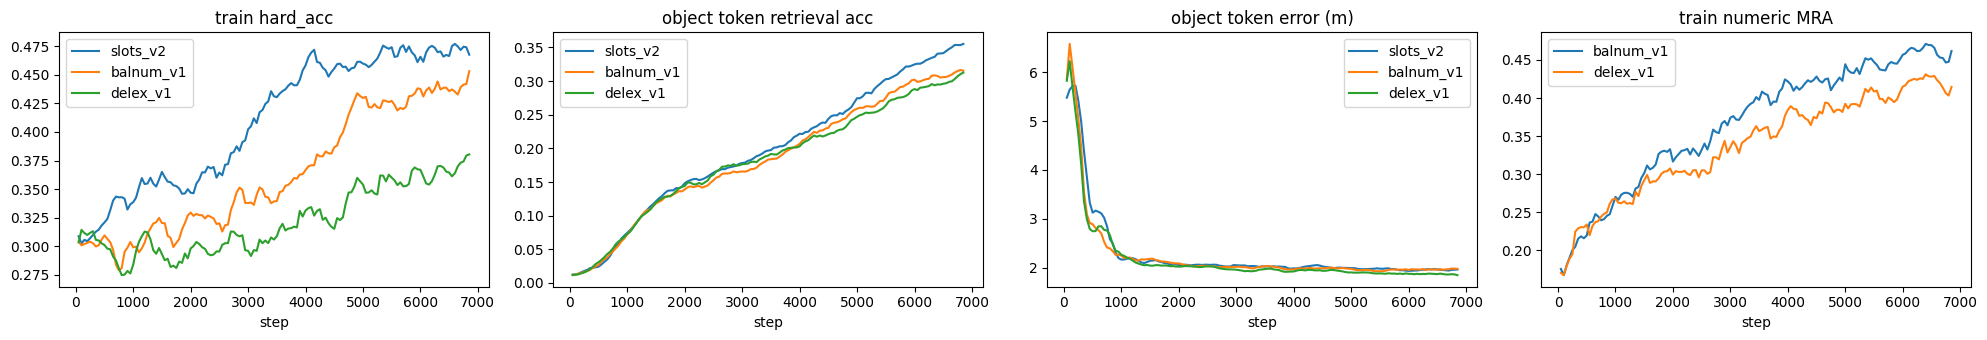

,val_hard_acc,val_slot_acc,val_slot_error_m
slots_v2,0.494,0.266,1.923
balnum_v1,0.431,0.235,1.930
delex_v1,0.424,0.233,1.898


In [5]:
read = lambda p: pd.DataFrame([json.loads(l) for l in open(p)])
logs = {"slots_v2": read("../../slots_v2/results/hardneg_log.jsonl"), "balnum_v1": read("../results/hardneg_log.jsonl"),
        "delex_v1": read("../../delex_v1/results/hardneg_log.jsonl")}
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5))
for name, n in logs.items():
    a = n.dropna(subset=["hard_acc"])
    ax[0].plot(a.step, a.hard_acc.rolling(5, min_periods=1).mean(), label=name)
    ax[1].plot(a.step, a.slot_acc.rolling(5, min_periods=1).mean(), label=name)
    ax[2].plot(a.step, a.slot_error_m.rolling(5, min_periods=1).mean(), label=name)
    if "numeric_mra" in a: ax[3].plot(a.step, a.numeric_mra.rolling(5, min_periods=1).mean(), label=name)
for x, t in zip(ax, ["train hard_acc", "object token retrieval acc", "object token error (m)", "train numeric MRA"]):
    x.set_title(t); x.set_xlabel("step"); x.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({name: n.filter(like="val_").dropna(how="all").iloc[-1][["val_hard_acc", "val_slot_acc", "val_slot_error_m"] + (["val_numeric_mra"] if "val_numeric_mra" in n else [])] for name, n in logs.items()}).T.astype(float).round(3)

训练集上的数值 MRA 到结束时约 0.45–0.49,仍在上升。物体 token 的定位误差三个模型都在 1.9 m 左右,没有因为这两项改动变好。

## 3 balnum_v1:配平 + 数值头

### 3.1 留出集(带名字)

In [6]:
print("长答案(随机 29.9)"); display(by_mode(RUNS, "holdout", "long/all"))
print("短答案"); display(by_mode(RUNS, "holdout", "short/all"))
by_type(RUNS, "holdout", lambda k: k.startswith("long/") and k != "long/all")

长答案(随机 29.9)


,real,shuffled,zero,slots_swapped,slots_none
slots_v2,48.1,44.5,44.4,46.8,37.8
balnum_v1,42.9,41.0,38.0,41.0,34.6
delex_v1,42.1,41.0,37.4,41.7,33.8


短答案


,real,shuffled,zero,slots_swapped,slots_none
slots_v2,40.6,39.6,40.1,39.1,34.9
balnum_v1,33.6,33.9,32.0,34.3,32.5
delex_v1,39.3,38.6,34.4,38.6,34.0


,题数,随机,slots_v2 real,slots_v2 real-shuffled,balnum_v1 real,balnum_v1 real-shuffled,delex_v1 real,delex_v1 real-shuffled
long/spar/appearance_order,1000.0,25.0,42.5,10.9,39.3,4.7,39.5,6.9
long/spar/spatial_imagination_oc_video_hard,1000.0,31.2,43.0,0.6,46.3,0.9,42.7,-0.1
long/spar/spatial_imagination_oo_video_hard,1000.0,13.3,23.5,-0.6,21.3,-0.8,24.4,1.6
long/vsi590k/appearance_order,632.0,25.0,49.2,9.0,43.5,9.3,45.6,4.1
long/vsi590k/relative_count,154.0,33.3,57.8,17.5,41.6,10.4,56.5,18.8
long/vsi590k/relative_direction_object,1000.0,37.3,46.6,0.5,36.1,0.2,40.9,-1.7
long/vsi590k/relative_distance_object,1000.0,25.0,45.2,4.4,32.6,-0.3,26.8,-4.4
long/vsi590k/relative_size_object,1000.0,50.0,85.9,0.8,81.6,0.5,73.7,-0.7


- 留出集本身没有配平,所以去掉先验后分数下降是预期内的:全零场景 44.4 → 38.0。
- 但真场景也掉了同样多(48.1 → 42.9),真场景减换场景的差没有变大(3.6 → 1.9)。配平没有换来更多的场景利用。
- slots_v2 里相对距离题"真槽 45.2、换槽 38.6"的差距,在 balnum_v1 里是 32.6 对 26.0,差距还在,但整体水平低了 12 个点:这类题的答案是物体名,配平压掉的正是"答椅子、门"的先验。
- 短答案 40.6 → 33.6,下降比长答案更大。

### 3.2 VSI-Bench 选择题

In [7]:
display(by_mode(RUNS, "vsibench_test_posed_f8", "all"))
by_type(RUNS, "vsibench_test_posed_f8")

,real,shuffled,zero,slots_swapped,slots_none
slots_v2,33.6,33.9,29.5,33.1,26.5
balnum_v1,29.0,29.1,20.9,31.4,24.7
delex_v1,35.7,35.8,24.3,36.6,23.2


,slots_v2 real,slots_v2 real-shuffled,balnum_v1 real,balnum_v1 real-shuffled,delex_v1 real,delex_v1 real-shuffled
all,33.6,-0.4,29.0,-0.1,35.7,-0.1
obj_appearance_order,37.5,0.3,39.0,0.6,40.5,0.6
object_rel_direction_easy,53.3,-4.2,51.7,-0.8,51.7,0.0
object_rel_direction_hard,15.6,2.6,17.3,0.9,23.8,-1.3
object_rel_direction_medium,35.0,0.4,14.0,0.4,44.0,-0.4
object_rel_distance,32.8,-1.8,25.0,0.0,28.5,0.7
route_planning,26.7,-1.1,24.4,-7.8,33.3,-5.6


- 三个模型在任何题型上真场景和换场景都没有差别(real-shuffled 在 ±3 以内)。
- 总分 33.6 / 29.0 / 35.7 的差别主要来自方向中等题(35.0 / 14.0 / 44.0)。四选一题掉到 14 说明模型固定偏向某个错误选项;这是选项偏向的移动,和场景无关。

### 3.3 VSI-Bench 数值题(数值头)

指标是 VSI-Bench 的 MRA。"中位数基线"是不看任何输入、总是回答训练集该类数值的中位数(计数 2 个、距离 1.9 m、尺寸 0.91 m、面积 19 m²)。

In [8]:
num = {k: v for k, v in RUNS.items() if "vsibench_test_numeric_posed_f8" in v["real"]}
rows = {}
for k, v in num["balnum_v1"]["real"]["vsibench_test_numeric_posed_f8"].items():
    row = {"题数": v["rows"], "中位数基线": 100 * v["median_mra"]}
    for name, r in num.items():
        for m in ("real", "shuffled", "zero", "slots_swapped"):
            row[f"{name} {m}"] = 100 * r[m]["vsibench_test_numeric_posed_f8"][k]["mra"]
    rows[k.replace("type/", "")] = row
pd.DataFrame(rows).T.astype(float).round(1)

,题数,中位数基线,balnum_v1 real,balnum_v1 shuffled,balnum_v1 zero,balnum_v1 slots_swapped,delex_v1 real,delex_v1 shuffled,delex_v1 zero,delex_v1 slots_swapped
all,1684.0,35.2,37.6,33.9,25.0,33.3,36.1,32.4,28.2,30.9
object_abs_distance,557.0,31.5,33.1,31.5,22.3,31.0,33.6,31.5,18.3,32.7
object_counting,399.0,59.6,42.5,37.6,36.8,41.4,36.3,32.8,50.6,30.1
object_size_estimation,590.0,23.7,35.0,35.2,23.0,25.4,35.6,34.4,27.9,25.7
room_size_estimation,138.0,29.1,53.1,27.5,9.9,53.1,48.0,26.7,4.4,48.0


- **房间面积**:53.1,换场景 27.5,中位数 29.1。这是整份报告里唯一明确由场景决定的结果。换槽不影响(这类题没有物体)。
- **计数**:42.5,比换场景高 4.9,但低于总答"2"的 59.6。配平把模型从"2"上推开了,而评测集里"2"仍然最多。
- **物体尺寸**:35.0,高于中位数 23.7,但与换场景相同(35.2),换槽后掉到 25.4。尺寸来自物体 token 里的图像特征和名字,不来自场景几何。
- **绝对距离**:33.1 对中位数 31.5,没有信号。
- 数值头训练时还没收敛(训练 MRA 仍在升)。

## 4 delex_v1:一半训练题去词汇化

训练时每道题有 50% 概率把题目、答案、错误选项里的物体名换成随机分配的 object A / B / ...(`jepa3d/delex.py`)。物体 token 仍然接在代号后面,所以代号指哪个物体只能从物体 token 得知。评测两遍:带名字、全部去词汇化。

### 4.1 带名字评测:见第 3 节各表的 delex_v1 列

留出集长答案 42.1(balnum_v1 42.9),短答案 39.3(33.6),数值题 36.1(37.6)。一半一半没有让带名字的评测变差。

### 4.2 去词汇化评测

In [9]:
print("留出集长答案(随机 29.9)"); display(by_mode(DELEX, "holdout", "long/all"))
print("VSI-Bench test 选择题"); display(by_mode(DELEX, "vsibench_test_posed_f8", "all"))
print("留出集各题型"); display(by_type(DELEX, "holdout", lambda k: k.startswith("long/") and k != "long/all"))
rows = {}
for name, r in list(RUNS.items()) + [(k + "(去词汇化评测)", v) for k, v in DELEX.items()]:
    rows[name] = {f"{m} {key}": r[m]["object_tokens"][key] * (100 if key == "acc" else 1)
                  for m in ("real", "shuffled", "slots_swapped") for key in ("acc", "error_m")}
print("物体 token:认出自己位置的准确率 % / 位置误差 m"); pd.DataFrame(rows).T.astype(float).round(2)

留出集长答案(随机 29.9)


,real,shuffled,zero,slots_swapped,slots_none
balnum_v1,29.1,29.4,30.0,30.1,30.8
delex_v1,30.7,30.3,29.1,30.5,29.9


VSI-Bench test 选择题


,real,shuffled,zero,slots_swapped,slots_none
balnum_v1,23.6,24.7,23.3,24.2,24.0
delex_v1,29.0,29.5,22.7,29.9,24.4


留出集各题型


,题数,随机,balnum_v1 real,balnum_v1 real-shuffled,delex_v1 real,delex_v1 real-shuffled
long/spar/appearance_order,1000.0,25.0,24.8,0.1,27.1,1.3
long/spar/spatial_imagination_oc_video_hard,1000.0,31.2,34.9,0.7,35.4,0.8
long/spar/spatial_imagination_oo_video_hard,1000.0,13.3,14.7,-0.8,14.5,0.1
long/vsi590k/appearance_order,632.0,25.0,25.8,-0.9,27.1,-2.5
long/vsi590k/relative_count,154.0,33.3,41.6,7.1,39.6,14.9
long/vsi590k/relative_direction_object,1000.0,37.3,26.9,-1.2,33.3,-0.8
long/vsi590k/relative_distance_object,1000.0,25.0,22.8,-2.7,23.3,0.3
long/vsi590k/relative_size_object,1000.0,50.0,50.5,0.9,51.3,0.2


物体 token:认出自己位置的准确率 % / 位置误差 m


,real acc,real error_m,shuffled acc,shuffled error_m,slots_swapped acc,slots_swapped error_m
slots_v2,26.04,1.93,1.20,2.85,1.00,2.81
balnum_v1,23.05,1.93,1.10,2.82,0.93,2.74
delex_v1,23.28,1.85,1.56,2.63,1.02,2.73
balnum_v1(去词汇化评测),22.70,1.94,1.10,2.81,0.85,2.73
delex_v1(去词汇化评测),23.22,1.84,1.54,2.63,1.01,2.73


- **去掉名字后是随机水平**:delex_v1 30.7,真场景、换场景、换槽、去掉物体 token 都在 30 上下。相对大小题从 73.7 掉到 51.3(二选一):带名字时的高分完全来自"门比椅子大"这类常识。
- **一半一半训练相对没训练过几乎没有帮助**:balnum_v1 从没见过代号,去词汇化评测 29.1;delex_v1 30.7。
- **物体 token 本身没有变差**:去词汇化评测下认出自己位置的准确率 23.2%、误差 1.84 m,和带名字时相同。所以问题不在物体 token 读不到场景,而在答题时没有用它来区分"object A 是哪个物体"。
- 这也回答了之前的疑问:一半一半没有让训练更难(带名字的分数没掉),但也没有起到预期的作用。

## 5 结论与下一步

1. **三项改动都没有让模型更多地使用场景。** 配平和去词汇化的作用是把先验拿掉,拿掉之后剩下的就是模型真正从场景得到的:留出集上约 1–2 个点,去词汇化后为 0。
2. **数值头可以保留。** 房间面积证明这条通路能读场景;其余三类的瓶颈和选择题相同(找不到题目说的物体)。
3. **去词汇化评测是一个干净的指标。** 它排除了名字先验,今后任何"让模型找到物体"的改动,都可以先看这个数是否离开 30。
4. **瓶颈仍然是物体 token 的定位和绑定**(1.9 m,认出自己位置 23%)。配平和去词汇化是在这个瓶颈解决之后才会起作用的手段。

可选的下一步(未定):
- 物体 token 的监督改成关系目标(两两距离结构),或把点提示头的特征放进物体 token;
- 场景 token 上的反向关系蒸馏(老师 dino.txt,patch–patch 加 patch–文本两项),先做小验证;
- 逐层的"文本找 patch"准确率诊断。